In [27]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data

import flash_amr_tools
import h5py

In [28]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/slices_x3a/"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new/BowShock_X3A"
# flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks"

In [38]:
fields = ["dens", "pres", "temp", "vel"]

field_lims = {
    "dens": [1e-22, 1e-18],
    "pres": [1e5, 1e9],
    "temp": [1e3, 1e8],
    "vel": [1e0, 1e4],
}

field_cmaps = {
    "dens": "viridis",
    "pres": "plasma",
    "temp": "inferno",
    "vel": "cividis",
}

field_labels = {
    "dens": r"Density [g cm$^{-3}$]",
    "pres": r"Pressure  / $k_B$ [K cm$^{-3}$]",
    "temp": r"Temperature [K]",
    "vel": r"Velocity [km s$^{-1}$]",
}

sim_dir = os.path.join(flash_output_dir)
sim_file = os.path.join(sim_dir, "starISM_hdf5_plt_cnt_0010")

In [39]:
blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

pf = h5py.File(sim_file)
ref_lvl = pf["refine level"][()][blist]
bbox = pf["bounding box"][()][blist]
bsize = pf["block size"][()][blist]

low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

# extent for imshow
extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

minimum position of the region of interest:  [-7.71419395e+16 -7.71419395e+16 -7.71419395e+16]
maximum position of the region of interest:  [2.31425819e+17 7.71419395e+16 7.71419395e+16]
Finding all leaf blocks in given region
912 912
Biggest block has refinement level: 3
Highest refinement level in simulation: 4
Highest refinement level in selected box: 4
Extending region to fit amr structure at level 3.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  8.0 4.0 4.0
Block shape:  (8, 4, 4)
Total number of blocks including parent blocks: 1024
Region extended to:	lower		upper
	x	-7.71419420e+16		+2.31425826e+17
	y	-7.71419420e+16		+7.71419420e+16
	z	-7.71419420e+16		+7.71419420e+16

Region center at:	+7.71419420e+16	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+16	+0.00000000e+00	+0.00000000e+00


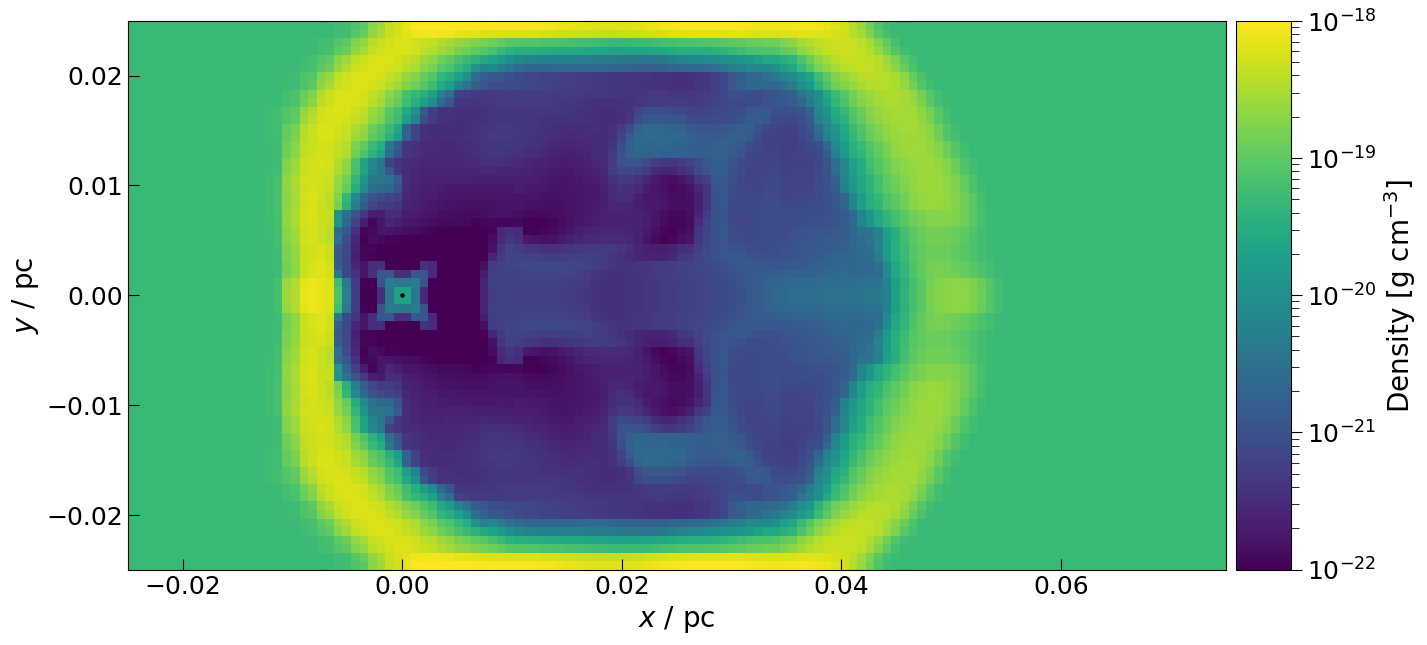

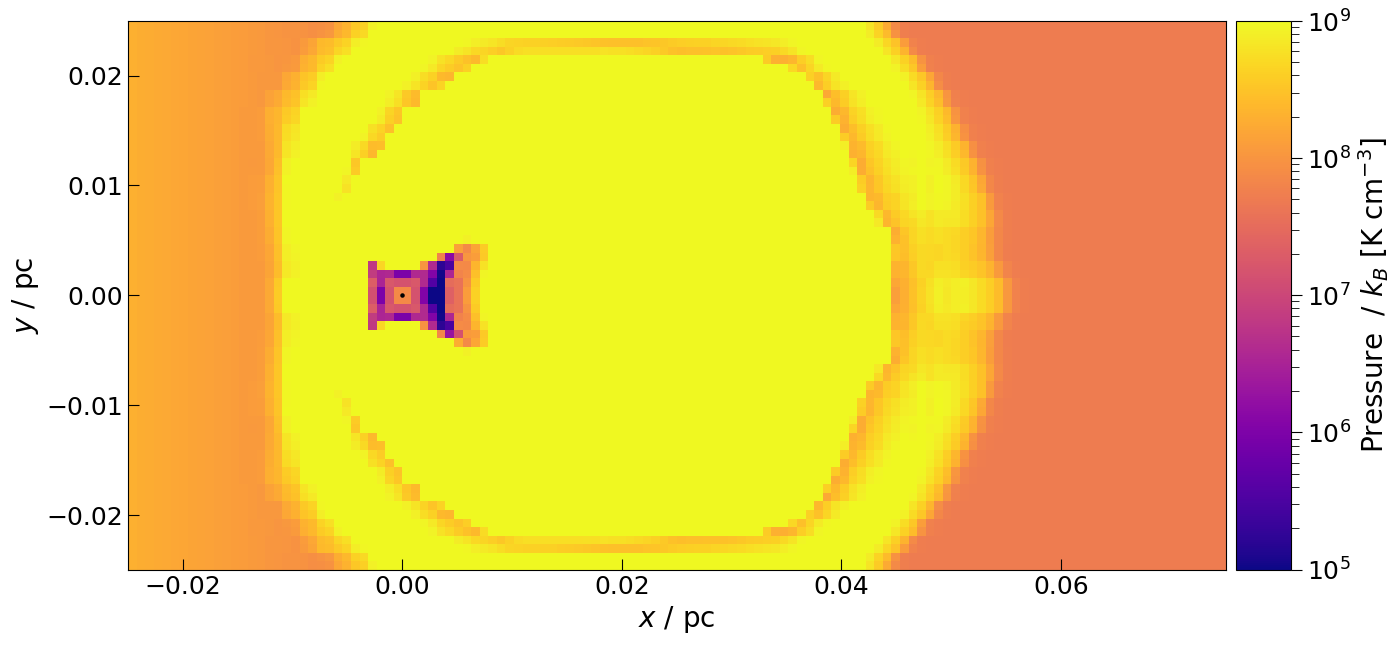

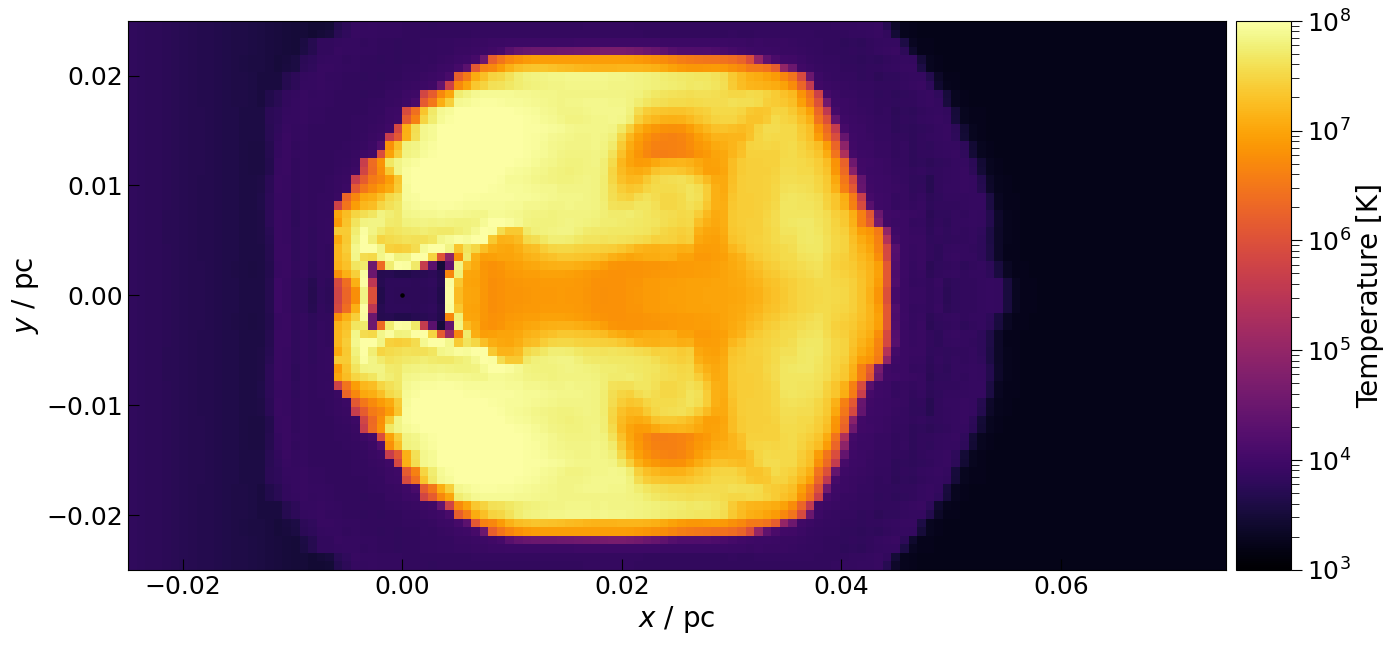

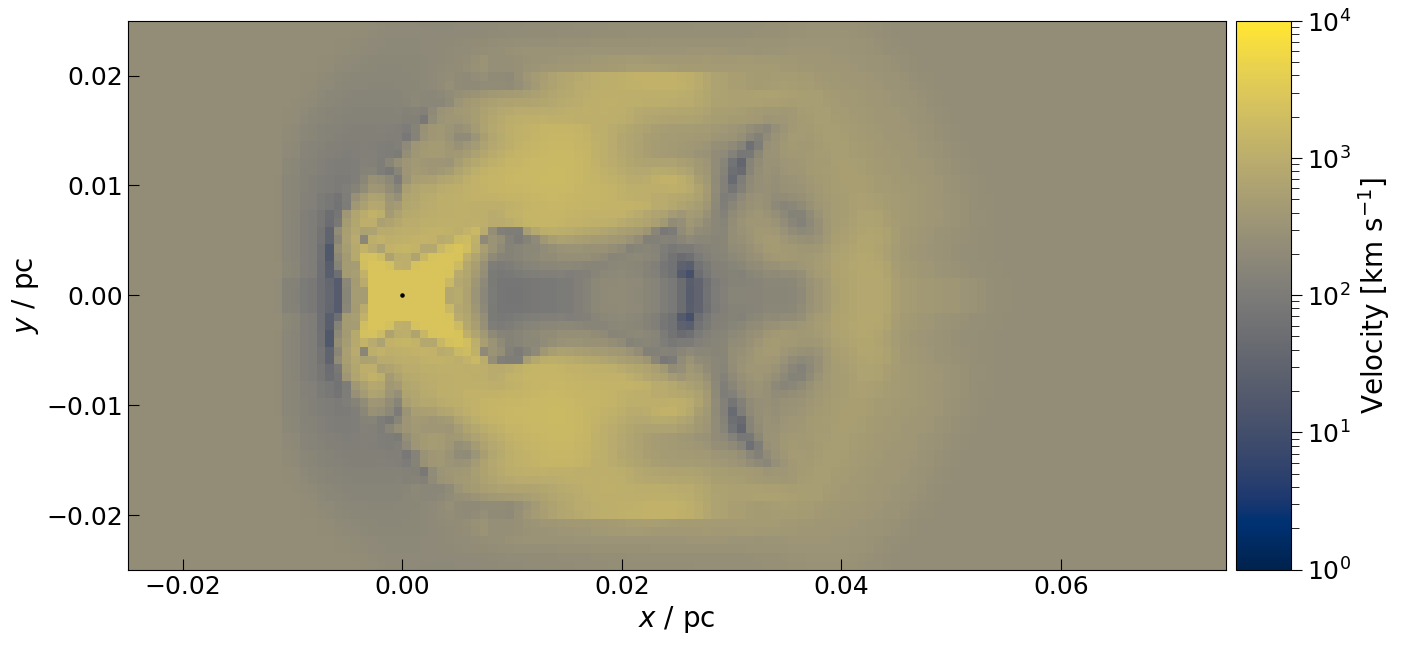

In [40]:
for ifield, field in enumerate(fields):

    field_data = get_transformed_data(pf, field, blist)
    field_slice = flash_amr_tools.get_slice(field_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

    # normaliztion for color
    norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)

    fig, ax = plt.subplots(figsize=(15,8))

    im = ax.imshow(field_slice.T, norm=norm, cmap=field_cmaps[field], origin="lower", extent=extent)
    ax.scatter(0, 0, s=5.0, color="k")

        # labels
    ax.set_xlabel("$x$ / pc", fontsize=20)
    ax.set_ylabel("$y$ / pc", fontsize=20)
    # ticks
    ax.tick_params(axis='both', direction="in", which='major', size=8, labelsize=18)
    ax.tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16)

    ax.set_xlim(-0.025, 0.075)
    ax.set_ylim(-0.025, 0.025)

    # colorbar
    # make separate axes for each image
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)

    cb = fig.colorbar(im, ax=ax, cax=cax)
    cb.ax.set_ylabel(field_labels[field], fontsize=20)
    cb.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
    cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

    # scales
    cb.ax.set_yscale("log")